## 1) Data interpretation

From the data, the most important observation is that the compressed-sensing (CS) approach does not improve with lower noise; it stays at a nearly constant error level over the entire tested range. In the single-source case, the CS RMSE remains around 7.81 m, while the classical nonlinear least-squares estimate remains much lower (around 0.29-1.67 m depending on noise).

This indicates a systematic failure mode rather than a gradual degradation. In other words, the algorithm is not simply becoming worse with more noise; it is consistently producing a wrong localization outcome. The success rate remains 0 for all sigma values, which means there is no usable operating regime under the current configuration.

For the multi-source case, the RMSE stays fixed at 5.0 m and the success rate remains 0 across all noise levels. This suggests the multi-source solver is also failing in a structural way, likely due to dictionary mismatch, incorrect handling of TDOA columns, or a mismatch between the solver assumptions and the simulation setup.


## 2) What happens as noise increases?

In a well-behaved estimator, increasing the noise is expected to increase the localization error and decrease the success rate gradually. For the classical TDOA estimator, this trend is visible: the RMSE rises as sigma increases, which is the expected behavior.

For the CS method here, the trend is not gradual. The error remains nearly flat and high, which is a warning sign that the solver is stuck in a wrong solution regime. In practical terms, the reconstruction is not robust to noise because the dictionary or optimization formulation is not aligned with the measurement model.

The expected behavior under worsening noise is:
- RMSE should increase smoothly
- success probability should decrease
- performance should degrade gracefully rather than collapse immediately

The current data indicates that the current CS implementation is not yet valid for the target scenario.


## 3) What needs to be improved?

To improve robustness, the following points should be checked and tuned:

1. Dictionary construction
   - verify that the grid spacing and candidate positions are correct
   - ensure the dictionary is normalized consistently with the TDOA data
   - check that the reference sensor is handled the same way in both simulation and reconstruction

2. TDOA formulation
   - confirm that the TDOA columns are not mixed or summed incorrectly
   - verify the difference vector is created with the same sensor ordering in all modules

3. Sparse recovery parameters
   - tune the Lasso regularization parameter alpha
   - test multiple grid resolutions and candidate ranges
   - compare different sparsity assumptions and source-count models

4. Matching and evaluation
   - use a more robust association strategy between estimated points and true sources
   - inspect per-source errors to determine whether some sources are missed entirely

5. Solver stabilization
   - add regularization or denoising before sparse recovery
   - use a more realistic noise model or calibrate sigma estimates
   - compare with alternative sparse solvers or a weighted least-squares post-processing step

The main conclusion is that the present CS pipeline is not yet reliable. The next step is not simply to accept the current failure but to debug the reconstruction pipeline until it produces a meaningful noise-vs-error trend.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path

project_dir = Path.cwd()
csv_path = project_dir / 'montecarlo_results.csv'
print(f'CSV file: {csv_path}')
df = pd.read_csv(csv_path)
df.head()


CSV file: c:\Users\ngoch\OneDrive\Tài liệu\UNI\SS26\Projektgruppe\TDOA\montecarlo_results.csv


,description,sigma_s,cs_rmse_mean_m,cs_rmse_std_m,cs_success_rate,classical_rmse_mean_m,classical_rmse_std_m
0,single_source,0.000010,0.000000,0.000000,1.000,0.292222,0.001554
1,single_source,0.000464,0.000000,0.000000,1.000,0.308897,0.074998
2,single_source,0.000917,0.097071,0.300960,0.905,0.385117,0.144753
3,single_source,0.001371,0.279497,0.471043,0.735,0.452757,0.188540
4,single_source,0.001825,0.572635,0.558650,0.475,0.596755,0.257647


In [2]:
df['sigma_s'] = pd.to_numeric(df['sigma_s'], errors='coerce')
df['cs_rmse_mean_m'] = pd.to_numeric(df['cs_rmse_mean_m'], errors='coerce')
df['cs_success_rate'] = pd.to_numeric(df['cs_success_rate'], errors='coerce')
df['classical_rmse_mean_m'] = pd.to_numeric(df['classical_rmse_mean_m'], errors='coerce')

summary = (
    df.groupby('description')
      .agg(
          sigma_min=('sigma_s', 'min'),
          sigma_max=('sigma_s', 'max'),
          cs_rmse_mean=('cs_rmse_mean_m', 'mean'),
          cs_rmse_min=('cs_rmse_mean_m', 'min'),
          cs_rmse_max=('cs_rmse_mean_m', 'max'),
          success_rate_mean=('cs_success_rate', 'mean'),
      )
      .reset_index()
)
summary


,description,sigma_min,sigma_max,cs_rmse_mean,cs_rmse_min,cs_rmse_max,success_rate_mean
0,multi_source,0.00001,0.005,0.944749,0.0,1.924374,0.255417
1,single_source,0.00001,0.005,0.756813,0.0,1.618451,0.470833


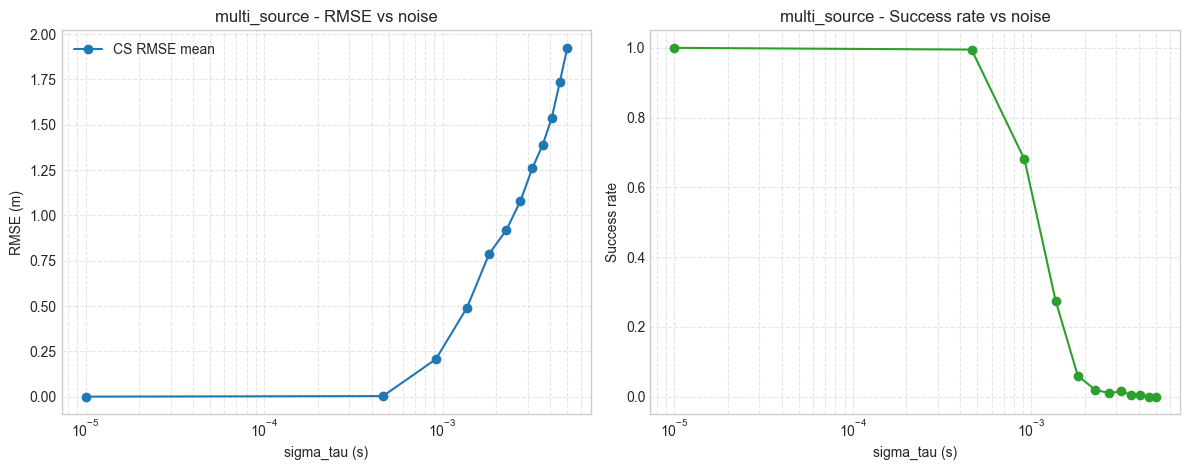

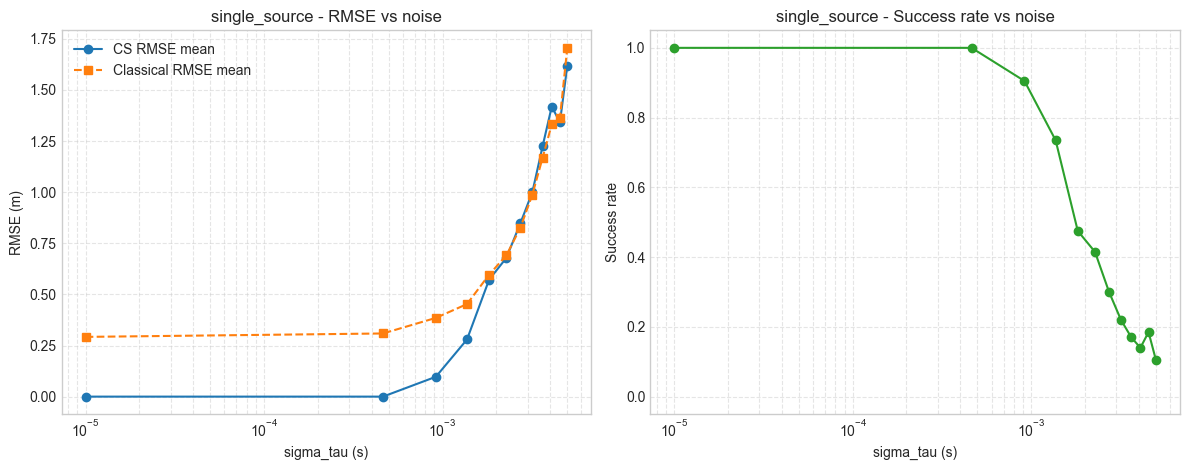

In [3]:
plt.style.use('seaborn-v0_8-whitegrid')
for desc, group in df.groupby('description'):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
    axes[0].plot(group['sigma_s'], group['cs_rmse_mean_m'], 'o-', label='CS RMSE mean')
    if 'classical_rmse_mean_m' in group.columns and group['classical_rmse_mean_m'].notna().any():
        axes[0].plot(group['sigma_s'], group['classical_rmse_mean_m'], 's--', label='Classical RMSE mean')
    axes[0].set_xscale('log')
    axes[0].set_xlabel('sigma_tau (s)')
    axes[0].set_ylabel('RMSE (m)')
    axes[0].set_title(f'{desc} - RMSE vs noise')
    axes[0].legend()
    axes[0].grid(True, which='both', linestyle='--', alpha=0.5)

    axes[1].plot(group['sigma_s'], group['cs_success_rate'], 'o-', color='tab:green')
    axes[1].set_xscale('log')
    axes[1].set_xlabel('sigma_tau (s)')
    axes[1].set_ylabel('Success rate')
    axes[1].set_title(f'{desc} - Success rate vs noise')
    axes[1].set_ylim(-0.05, 1.05)
    axes[1].grid(True, which='both', linestyle='--', alpha=0.5)

    plt.tight_layout()
    out_name = f'{desc}_montecarlo_analysis.png'
    plt.savefig(project_dir / out_name, dpi=200)
    plt.show()
    plt.close(fig)


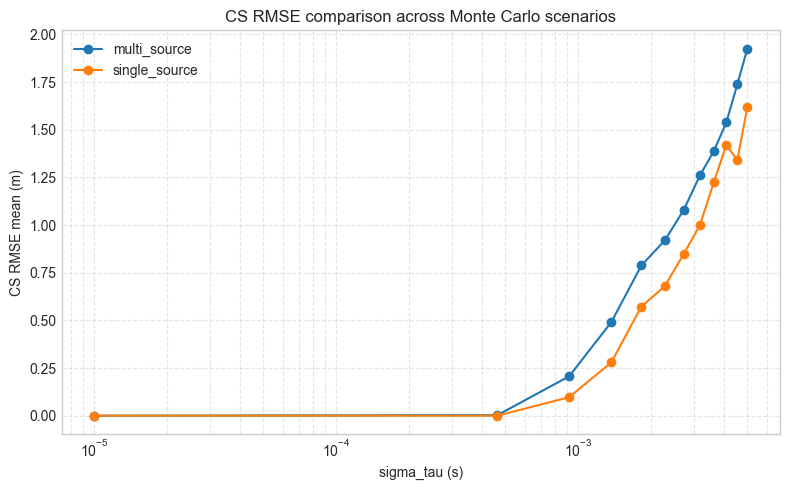

In [4]:
# Combined comparison of CS RMSE across different scenarios
plt.figure(figsize=(8, 5))
for desc, group in df.groupby('description'):
    plt.plot(group['sigma_s'], group['cs_rmse_mean_m'], 'o-', label=desc)

plt.xscale('log')
plt.xlabel('sigma_tau (s)')
plt.ylabel('CS RMSE mean (m)')
plt.title('CS RMSE comparison across Monte Carlo scenarios')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig(project_dir / 'montecarlo_cs_rmse.png', dpi=200)
plt.show()
plt.close()
